# Problem 3.9

Choose a problem that you are familiar with and find the magnitude of numerical noise in one or more outputs of interest with respect to one or more inputs of interest. What means do you have to decrease the numerical noise? What is the lowest possible level of noise you can achieve?

In [6]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Approach

In [7]:
# implementation of example 3.3 from the book (p.51)
def residuals(u):
    u1, u2 = u
    return np.array(
        [u1**2 + 2*u2 - 1,
         u1 * np.cos(u1) - u2])

def jacobian(u):
    u1, u2 = u
    return np.array([[2*u1, 2],
                     [np.cos(u1) - u1 * np.sin(u1), -1]])

def function(u):
    return u[0] + u[1]

def solve_system(u0, max_iter=30, tol=1e-7, table=True):
    u = u0
    history = [] # (iteration, u, residuals)
    converged = False
    for i in range(max_iter):
        r = residuals(u)
        history.append((i, u, r))
        J = jacobian(u)
        du = np.linalg.solve(J, -r)
        if np.linalg.norm(du) < tol:  # convergence criterion
            converged = True
            break
        u = u + du

    if table:
        print(f"{'iter':>4} {'u1':>14} {'u2':>14} {'r':>14}")
        for i_k, u_k, r_k in history:
            print(f"{i_k:4d} {u_k[0]:14.8f} {u_k[1]:14.8f} {np.linalg.norm(r_k):14.8f}")
        print(f"{'converged' if converged else 'NOT converged'} after {i} iterations")
    return u, history, converged

solve_system([2.0, 1.0], table=True);

iter             u1             u2              r
   0     2.00000000     1.00000000     5.32515728
   1     4.84443009    -7.18886018    11.25688581
   2     3.63031316    -5.35254684     2.60450770
   3     2.98242694    -3.73755697     0.89709103
   4     2.32377799    -1.98306285     0.58604832
   5    13.31346159   -27.73755695   126.46262186
   6    -6.26280411   172.50373174   422.87395196
   7    -3.76058202    -3.44043086     9.02742500
   8     0.26507792     8.56783582    18.21323813
   9     0.44518206     0.41712522     0.03587930
  10     0.44441674     0.40124717     0.00000069
  11     0.44441681     0.40124685     0.00000000
converged after 11 iterations


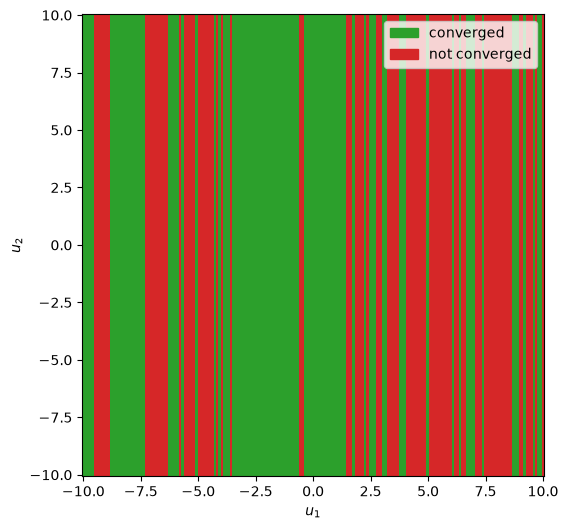

In [8]:
# checking which strating values converge

import io
from contextlib import redirect_stdout
from matplotlib.colors import ListedColormap

def converged_at(u0):
    try:
        with redirect_stdout(io.StringIO()):       # silence the per-call printing
            _, _, converged = solve_system(u0, max_iter=10, table=False)
    except np.linalg.LinAlgError:                  # singular Jacobian
        return False
    return converged

axis = np.linspace(-10.0, 10.0, 200)
g1, g2 = np.meshgrid(axis, axis)
with np.errstate(all="ignore"):
    ok = np.array([converged_at(p) for p in np.column_stack([g1.ravel(), g2.ravel()])]).reshape(g1.shape)

fig, ax = plt.subplots(figsize=(6, 6))
ax.pcolormesh(g1, g2, ok, cmap=ListedColormap(["tab:red", "tab:green"]), shading="auto")
ax.set_xlabel("$u_1$")
ax.set_ylabel("$u_2$")
ax.set_aspect("equal")
ax.legend(
    handles=[
        plt.Rectangle((0, 0), 1, 1, color="tab:green", label="converged"),
        plt.Rectangle((0, 0), 1, 1, color="tab:red", label="not converged"),
    ],
    loc="upper right",
)
plt.show()

with only 10 iterations there are a lot of combinations of u that dont converge. increasing the iterations lets more values of u converge gaps still remain.

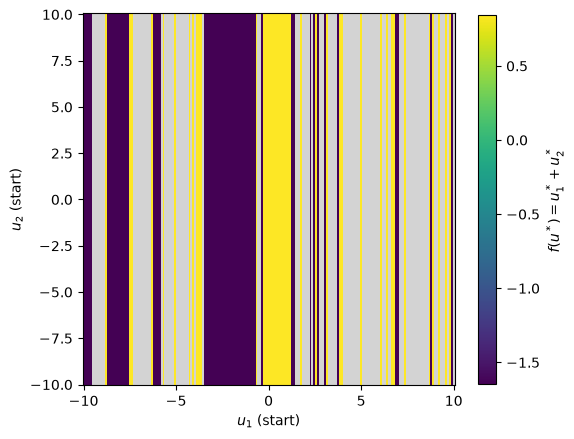

[-1.647765  0.845664]


In [9]:
def value_at(u0):
    try:
        u_sol, _, ok = solve_system(u0, max_iter=10, table=False)
    except np.linalg.LinAlgError:                  # singular Jacobian
        return np.nan
    return function(u_sol) if ok else np.nan

axis = np.linspace(-10.0, 10.0, 200)
g1, g2 = np.meshgrid(axis, axis)
with np.errstate(all="ignore"):
    values = np.array([value_at(p) for p in np.column_stack([g1.ravel(), g2.ravel()])]).reshape(g1.shape)

fig, ax = plt.subplots(figsize=(6, 6))
pcm = ax.pcolormesh(g1, g2, values, cmap="viridis", shading="auto")
fig.colorbar(pcm, ax=ax, shrink=0.8, label="$f(u^*) = u_1^* + u_2^*$")
ax.set_facecolor("lightgray")                      # NaN (not converged) shows as gray
ax.set_xlabel("$u_1$ (start)")
ax.set_ylabel("$u_2$ (start)")
ax.set_aspect("equal")
plt.show()

print(np.unique(np.round(values[~np.isnan(values)], 6)))   # distinct values f reaches


these are the values reached

## Interpretation